# SkinScreen — AID427 Phase 1
**Multimodal skin cancer classification from smartphone images and patient data (PAD-UFES-20)**

Team: Nouran Ahmed (320230066), Belal Salah (320230075) — AID2

## 1. Problem introduction
Skin cancer is among the most common cancers worldwide. Many patients, especially in rural and low-income areas, cannot easily see a dermatologist, so dangerous lesions are often found late. We combine a smartphone photo of the lesion with the patient's clinical information to classify the lesion into **6 diagnoses**: three cancers (BCC, SCC, MEL) and three non-cancer or pre-cancer lesions (ACK, NEV, SEK). We also report a cancer vs non-cancer view to support referral. The model is meant as a screening aid, not a diagnosis.

## 2. Dataset
PAD-UFES-20 (Pacheco et al., *Data in Brief* 2020): 2,298 images from 1,641 lesions and 1,373 patients, with 26 metadata fields per image. We use 21 clinical features after dropping IDs, the target and the leakage-prone `biopsed` column.
**Why it is difficult and noisy:** missing and `UNK` answers, severe class imbalance (BCC 845 vs MEL 52), non-standard smartphone photos (different devices, lighting and angles), look-alike classes, label noise (only 58.4 % of diagnoses are biopsy-proven), and several images per patient (leakage risk).

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config
from src.data_loading import load_dataset, missing_indicator_cols
from src.image_features import attach_image_features
from src.preprocessing import build_preprocessor, patient_split, split_summary
config.ensure_dirs()
show = lambda name: display(Image(filename=str(config.FIG_DIR / f"{name}.png")))
FAST = False   # True = smaller searches for a quick run

In [4]:
df, miss_report = load_dataset(config.DATA_DIR)
df, image_cols = attach_image_features(df, use_cnn=False)
ind_cols = missing_indicator_cols(df)
display(df.head()); display(miss_report)

[23:26:02] Loaded metadata: 2298 rows x 26 columns
[23:26:02] Final dataset: 2298 images, 1373 patients, 1641 lesions
[23:26:02] Extracting hand-crafted features from 2298 images ...
[23:26:47]   80 features per image (cached to image_features.csv)


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,img_lesion_contrast_L,img_lesion_std_L,img_lesion_contrast_a,img_lesion_std_a,img_lesion_contrast_b,img_lesion_std_b,q_width,q_height,q_brightness,q_sharpness
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,-14.806667,4.450129,5.276071,2.619231,11.044896,10.776840,1089,1089,0.476933,0.007650
1,PAT_46,881,0.0,0.0,POMERANIA,POMERANIA,55,0.0,FEMALE,1.0,...,-13.258479,4.265453,6.260746,4.879424,5.725087,3.697497,1325,1325,0.557222,0.013987
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,-27.324291,8.683419,11.565640,3.963542,0.449261,2.652811,640,640,0.501030,0.025024
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,-16.270183,5.511920,2.103629,2.631449,9.646411,5.935594,2118,2117,0.611204,0.016444
4,PAT_684,1302,0.0,1.0,POMERANIA,POMERANIA,79,0.0,MALE,1.0,...,-11.053123,4.006267,4.103960,4.255102,3.219826,3.574161,896,896,0.470246,0.016660


,blank,UNK,total_missing,pct_missing
feature,,,,
background_father,818,95,913,39.730200
background_mother,822,84,906,39.425587
diameter_1,804,0,804,34.986945
diameter_2,804,0,804,34.986945
fitspatrick,804,0,804,34.986945
has_sewage_system,804,0,804,34.986945
gender,804,0,804,34.986945
smoke,804,0,804,34.986945
drink,804,0,804,34.986945


## 3. Data analysis and preprocessing (EDA)

[23:26:47] === EDA ===
[23:26:47]   table  -> outputs/tables/eda_overview.csv
[23:26:48]   figure -> outputs/figures/eda_01_class_distribution.png
[23:26:48]   table  -> outputs/tables/eda_class_distribution.csv
[23:26:48]   figure -> outputs/figures/eda_02_missing_values.png
[23:26:48]   table  -> outputs/tables/eda_missing_values.csv
[23:26:51]   figure -> outputs/figures/eda_03_numeric_features.png
[23:26:51]   table  -> outputs/tables/eda_numeric_summary_outliers.csv
[23:26:52]   figure -> outputs/figures/eda_04_categorical_features.png
[23:26:52]   figure -> outputs/figures/eda_05_binary_features.png
[23:26:52]   table  -> outputs/tables/eda_binary_prevalence.csv
[23:26:54]   figure -> outputs/figures/eda_06_correlation.png
[23:26:54]   figure -> outputs/figures/eda_07_images_per_patient.png
[23:26:55]   figure -> outputs/figures/eda_08_image_quality.png
[23:26:55]   table  -> outputs/tables/eda_image_quality.csv
[23:26:58]   figure -> outputs/figures/eda_09_sample_images.png


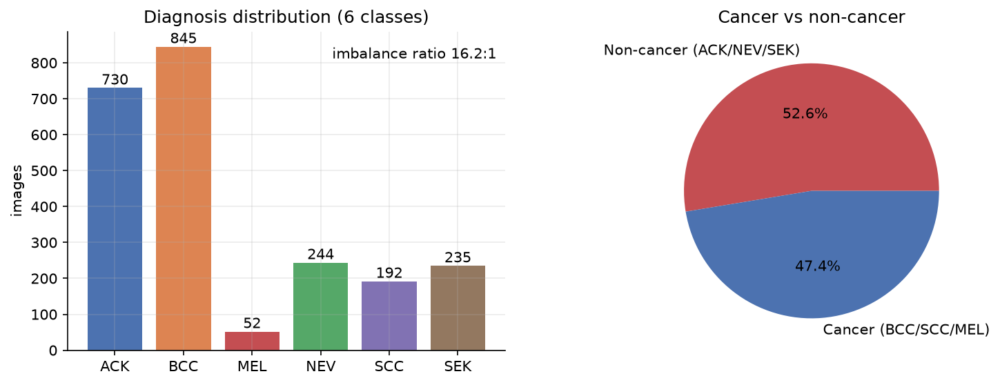

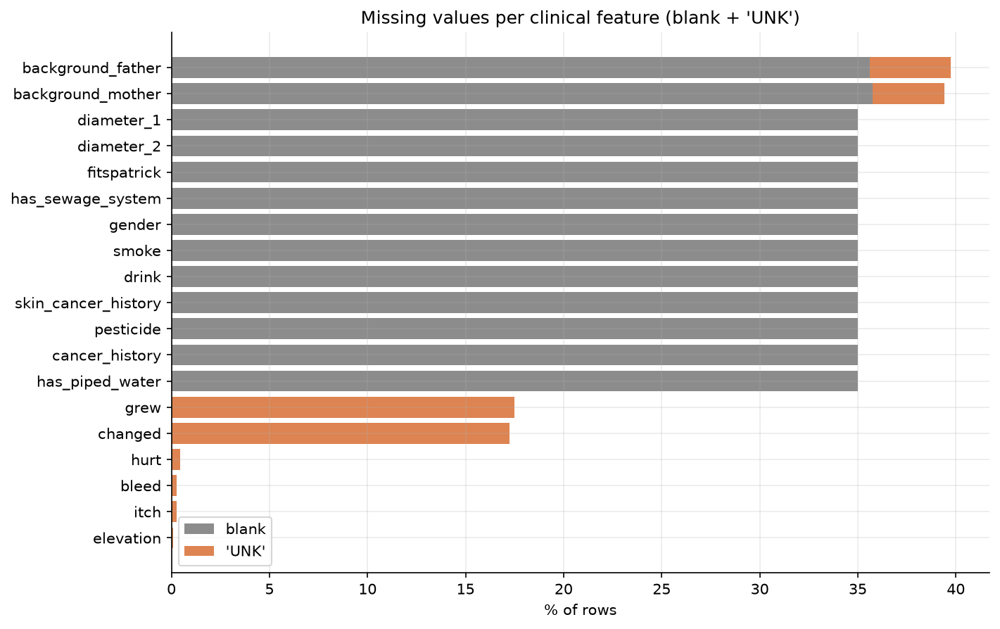

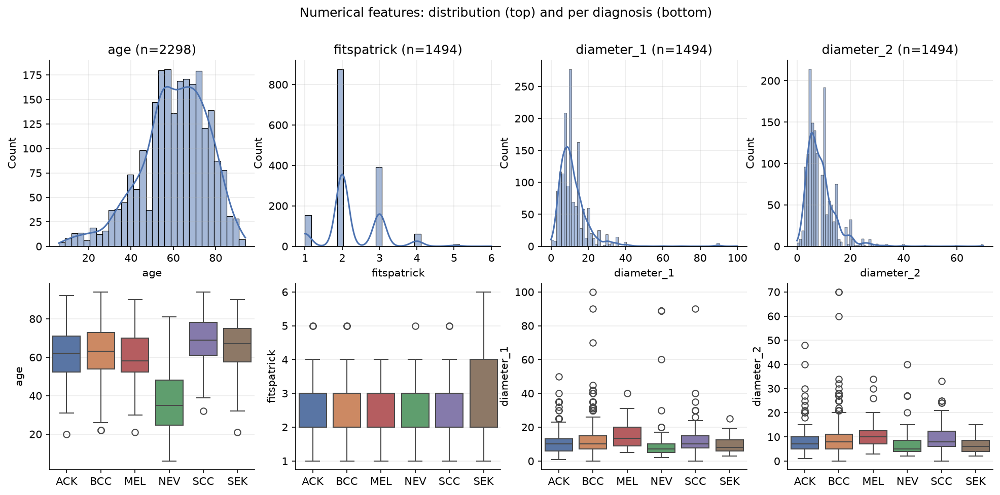

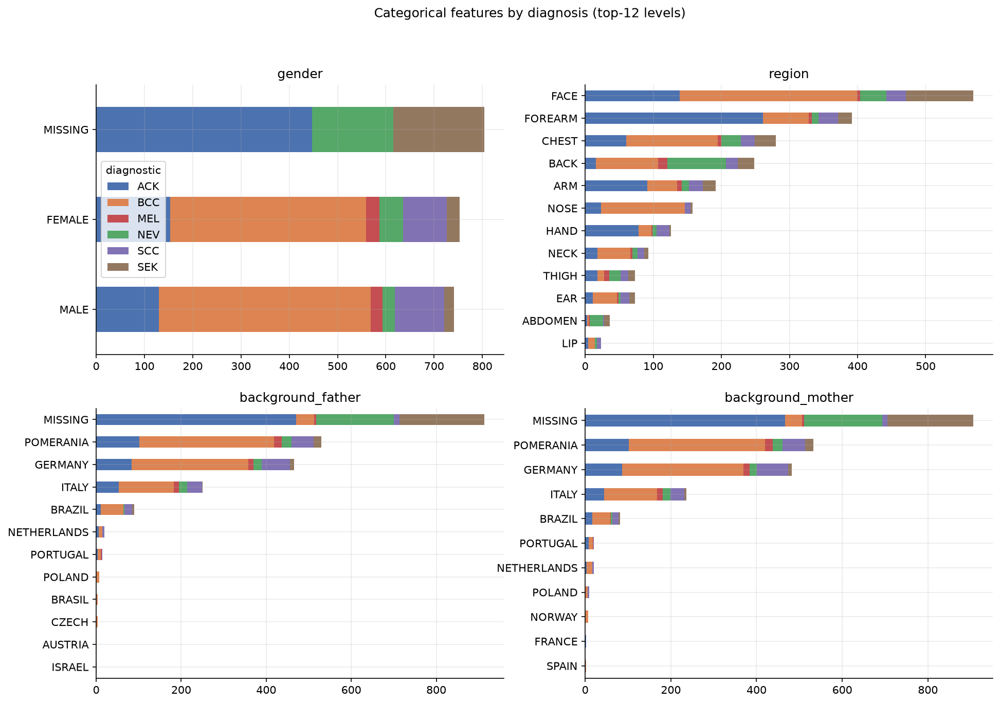

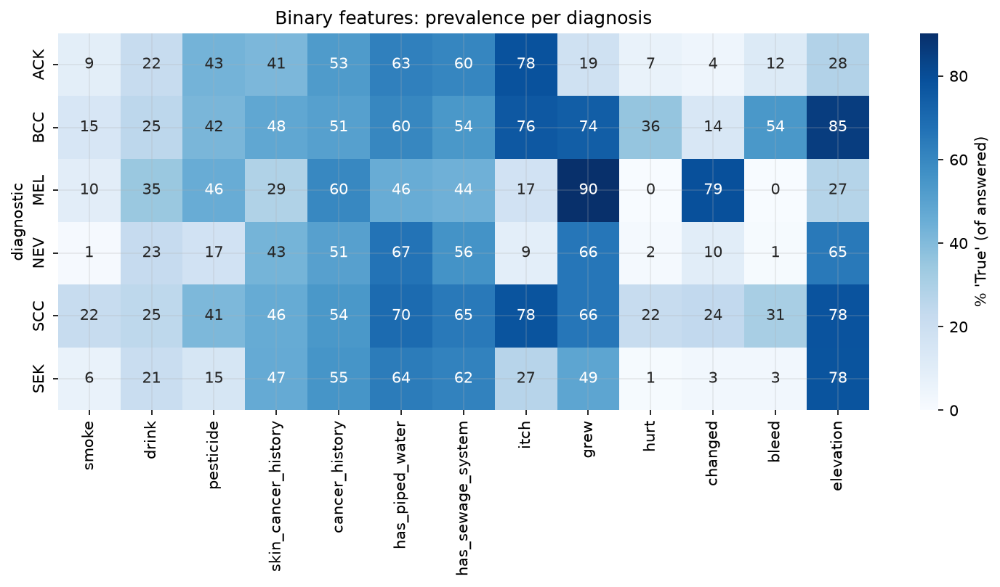

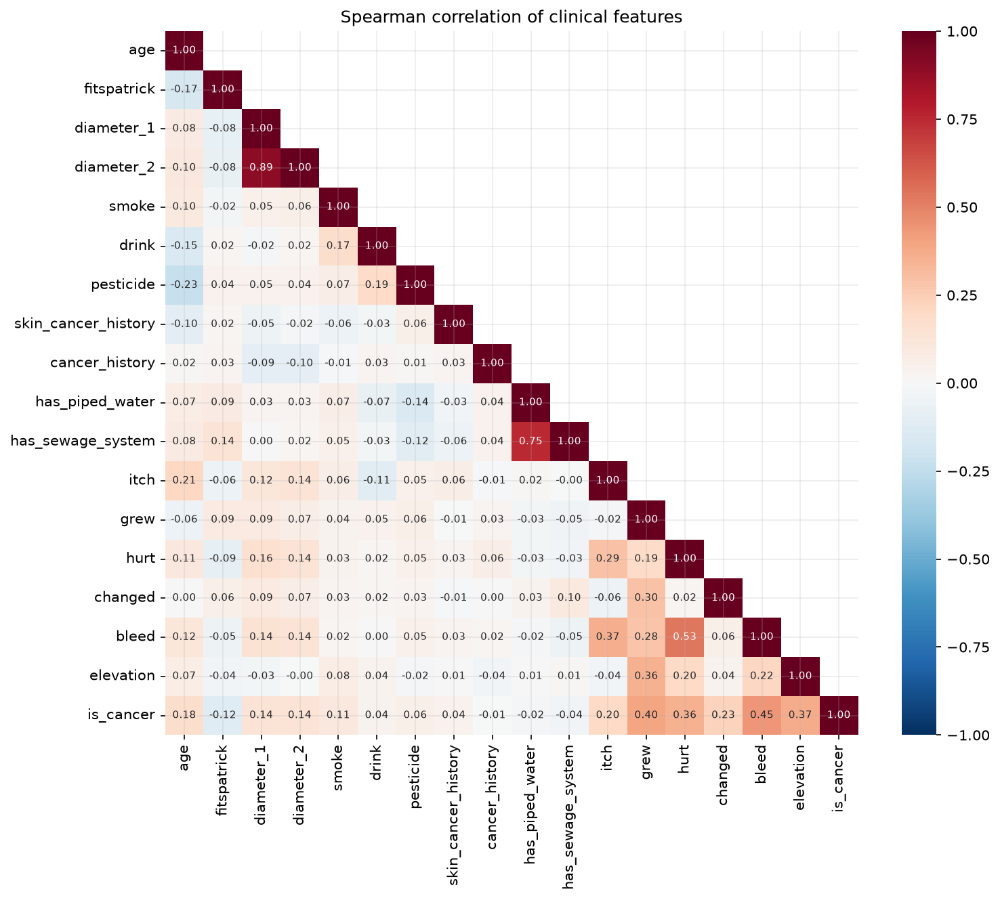

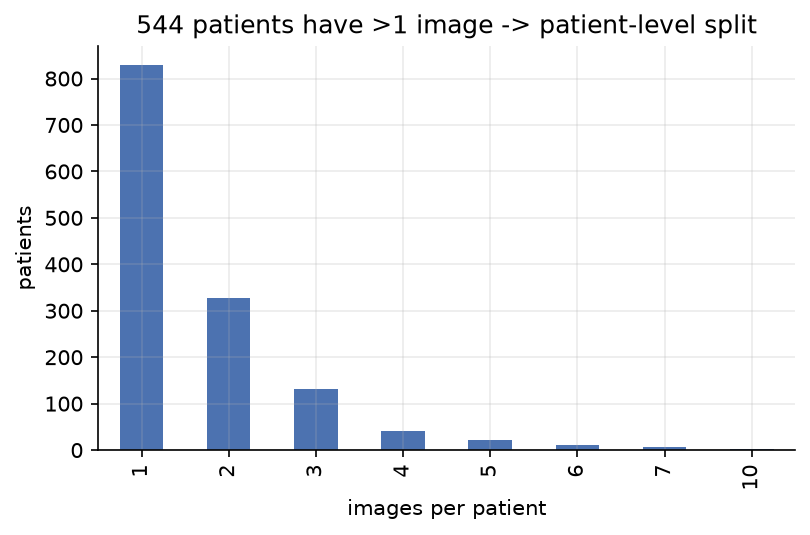

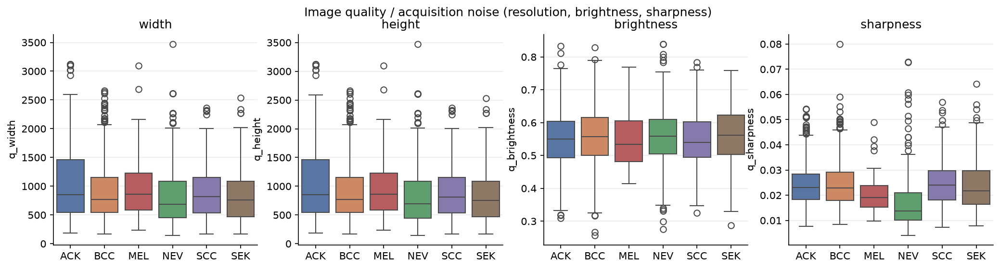

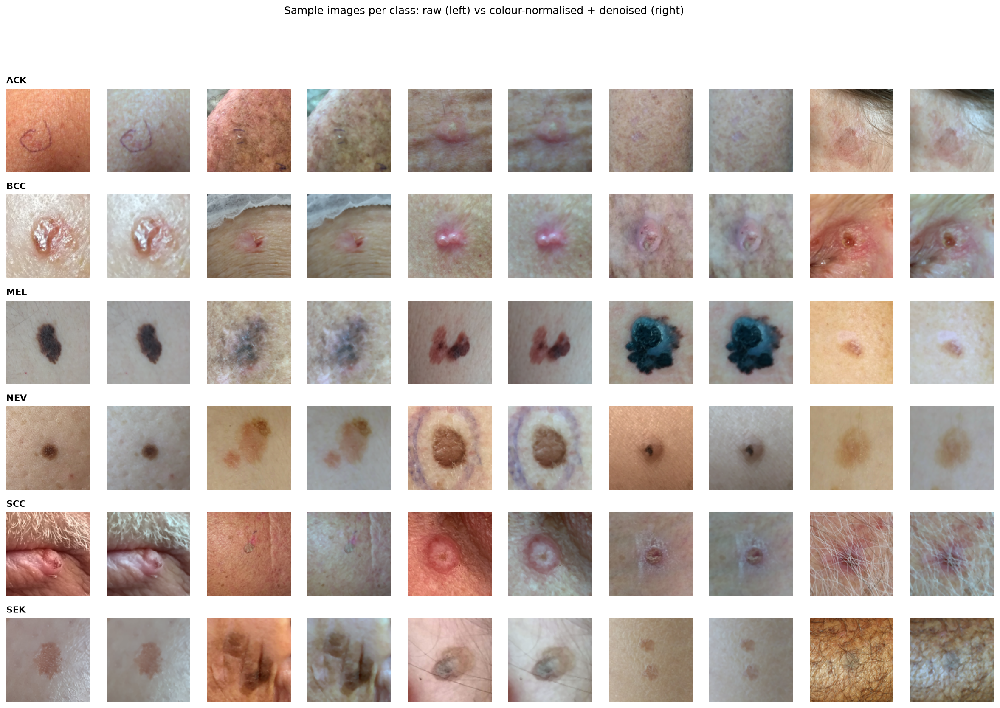

In [5]:
from src.eda import run_eda
run_eda(df, miss_report)
for f in ["eda_01_class_distribution","eda_02_missing_values","eda_03_numeric_features",
          "eda_04_categorical_features","eda_05_binary_features","eda_06_correlation",
          "eda_07_images_per_patient","eda_08_image_quality","eda_09_sample_images"]:
    show(f)

### Preprocessing
* Patient-level, stratified **80/20 split**: no patient appears in both sets.
* Numeric: 3×IQR winsorising → median imputation → standardisation. Categorical: `MISSING` level → one-hot. Binary: mode imputation. Every incomplete column also gets a `_missing` indicator.
* Images: resize to 128×128 → Shades-of-Gray colour constancy → median filter → colour, texture (GLCM, LBP) and lesion-shape features.

In [6]:
train, test = patient_split(df)
display(split_summary(train, test))
C = config.CLASSES
ytr = train[config.TARGET].map(C.index).to_numpy(); yte = test[config.TARGET].map(C.index).to_numpy()
ytr_lbl = train[config.TARGET].to_numpy()
make_prep = lambda tab=True, img=True: build_preprocessor(df, image_cols, ind_cols, tab, img)
prep = make_prep()
Xtr = prep.fit_transform(train); Xte = prep.transform(test)
Xtr.shape, Xte.shape

[23:26:59] Patient-level split: train=1838 (80%) test=460 (20%), no shared patients


,train,test,train_%,test_%
diagnostic,,,,
ACK,584,146,31.8,31.7
BCC,676,169,36.8,36.7
MEL,42,10,2.3,2.2
NEV,195,49,10.6,10.7
SCC,153,39,8.3,8.5
SEK,188,47,10.2,10.2


((1838, 153), (460, 153))

## 4. Linear feature reduction: PCA, LDA, SVD

[23:27:39] === Linear feature reduction (PCA, LDA, SVD) ===
[23:27:39]   figure -> outputs/figures/red_01_pca_variance.png
[23:27:40]   figure -> outputs/figures/red_02_pca_loadings.png
[23:27:41]   table  -> outputs/tables/red_linear_summary.csv
[23:27:41]   table  -> outputs/tables/red_lda_variance.csv
[23:27:41]   figure -> outputs/figures/red_03_linear_2d.png


,type,var. explained by 2 comps,comps for 95% var
method,,,
PCA,"unsupervised, linear",0.335869,40.0
LDA,"supervised, linear (max C-1=5 comps)",0.778453,NaN
SVD,"unsupervised, linear, no centring",0.335777,41.0


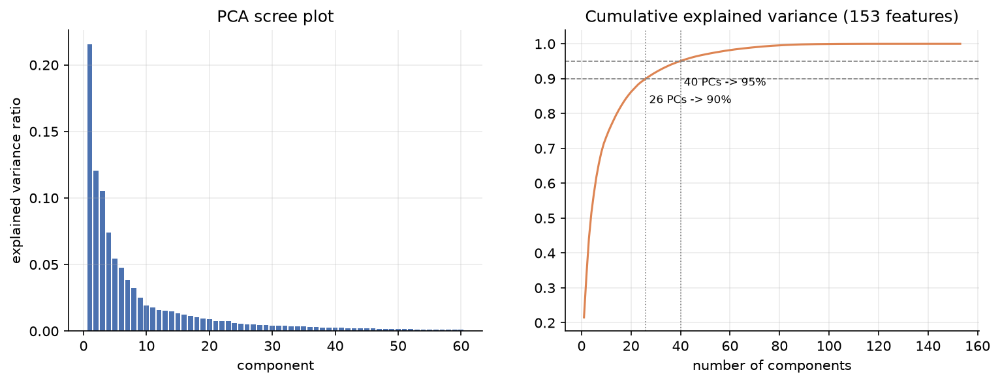

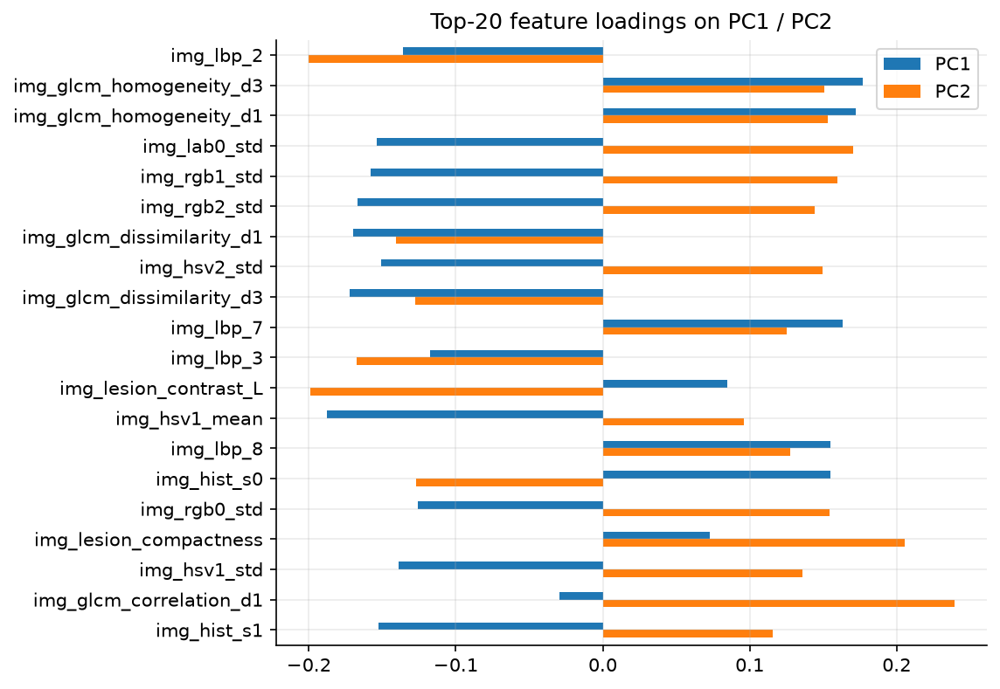

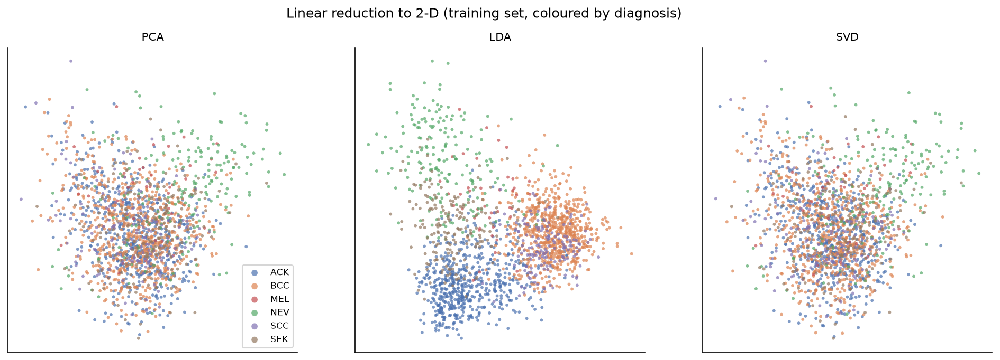

In [7]:
from src import reduction
lin = reduction.linear_reduction(Xtr, ytr_lbl)
display(pd.read_csv(config.TABLE_DIR / "red_linear_summary.csv", index_col=0))
for f in ["red_01_pca_variance","red_02_pca_loadings","red_03_linear_2d"]: show(f)

## 5. Non-linear feature reduction: Kernel PCA, SNE, t-SNE, UMAP, metric & non-metric MDS, Isomap, LLE

[23:27:41] === Non-linear feature reduction ===
[23:27:42]   Kernel PCA (RBF)   n=1838     0.3s  kNN-BAcc=0.265
[23:27:43]   Kernel PCA (poly)  n=1838     0.3s  kNN-BAcc=0.244
[23:28:15]   SNE                n=1000    31.9s  kNN-BAcc=0.324
[23:28:22]   t-SNE              n=1838     7.1s  kNN-BAcc=0.399
[23:28:42]   Metric MDS         n=1500    19.4s  kNN-BAcc=0.253
[23:32:33]   Non-metric MDS     n=1500   231.2s  kNN-BAcc=0.244
[23:32:35]   Isomap             n=1838     1.2s  kNN-BAcc=0.347
[23:32:37]   LLE                n=1838     1.0s  kNN-BAcc=0.269
[23:32:56]   UMAP               n=1838    19.3s  kNN-BAcc=0.380
[23:32:57]   table  -> outputs/tables/red_nonlinear_quality.csv
[23:32:57]   figure -> outputs/figures/red_04_nonlinear_2d_diagnosis.png
[23:32:58]   figure -> outputs/figures/red_04_nonlinear_2d_cancer.png
[23:32:59]   figure -> outputs/figures/red_06_sne_convergence.png


,n_samples,time_s,trustworthiness@10,silhouette(true labels),kNN balanced acc (5-fold)
method,,,,,
Kernel PCA (RBF),1838,0.3,0.7522,-0.0684,0.2653
Kernel PCA (poly),1838,0.3,0.7878,-0.0600,0.2439
SNE,1000,31.9,0.8160,-0.1008,0.3238
t-SNE,1838,7.1,0.9495,-0.0646,0.3993
Metric MDS,1500,19.4,0.8040,-0.0442,0.2529
Non-metric MDS,1500,231.2,0.8028,-0.0552,0.2443
Isomap,1838,1.2,0.7937,-0.0663,0.3473
LLE,1838,1.0,0.6584,-0.1570,0.2686
UMAP,1838,19.3,0.9062,-0.1139,0.3801


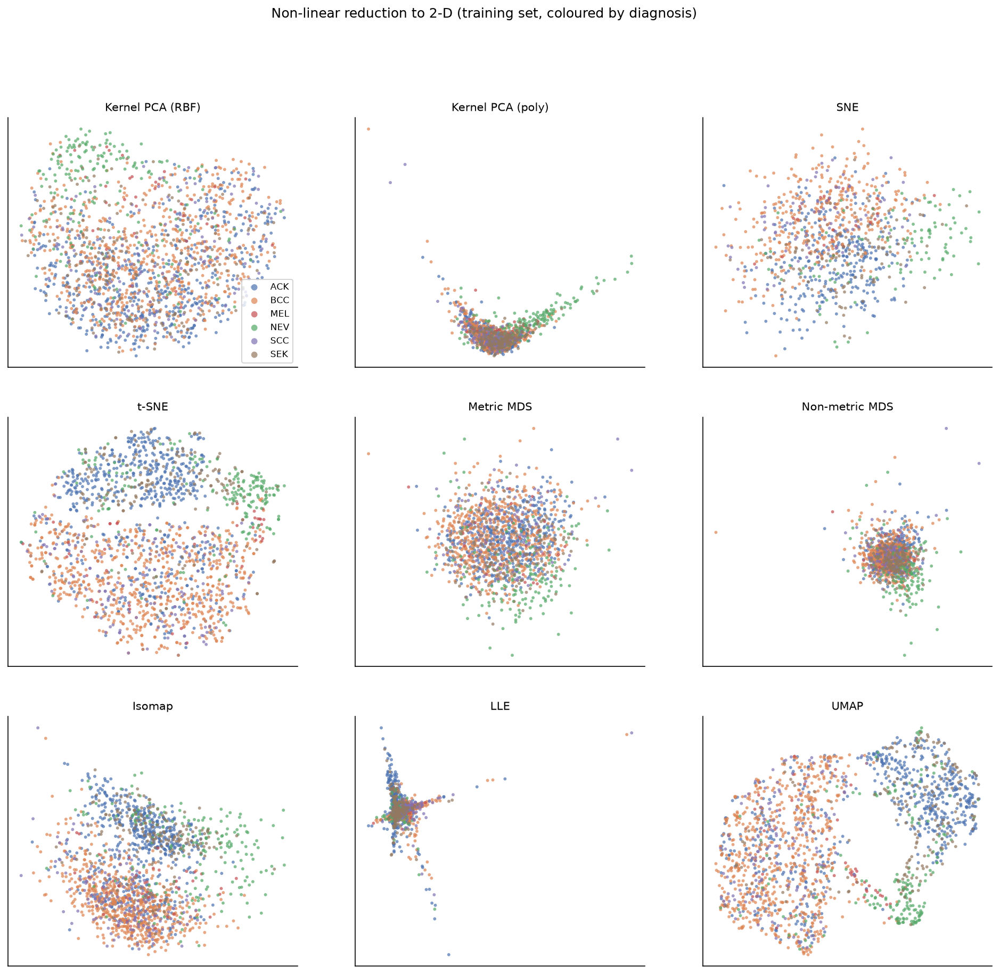

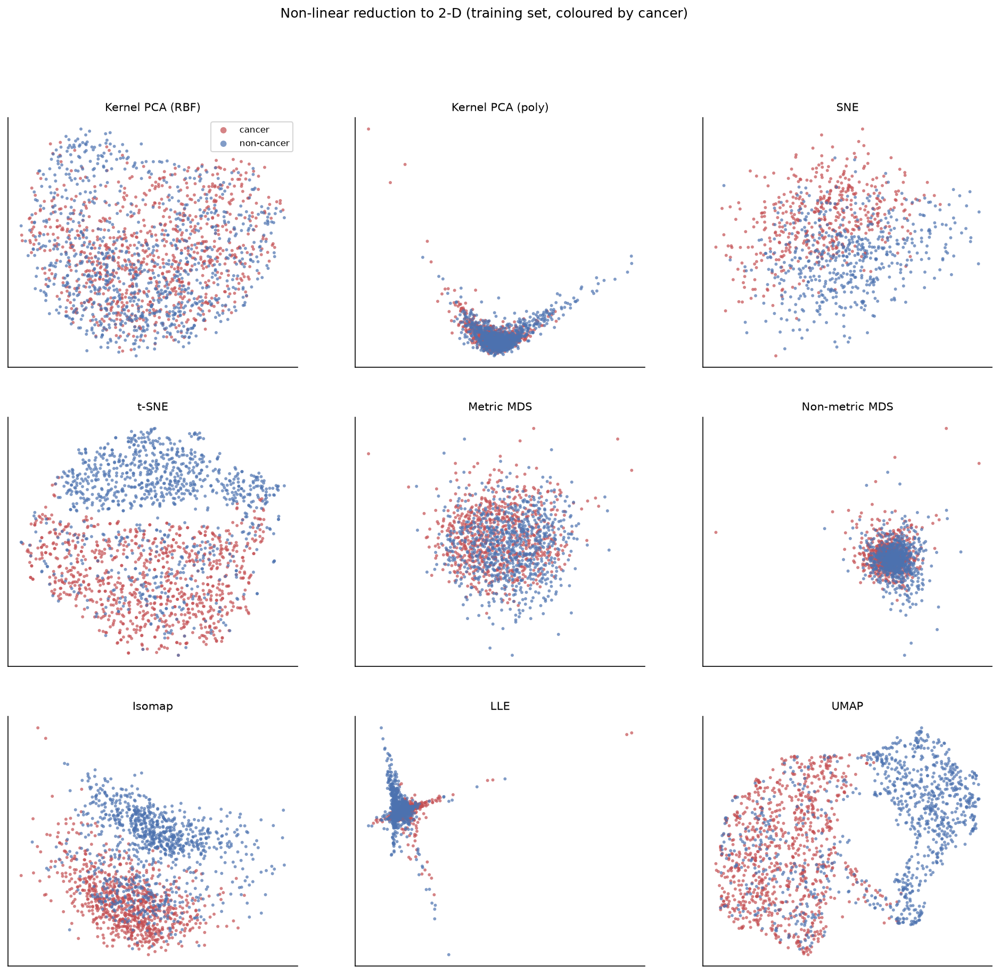

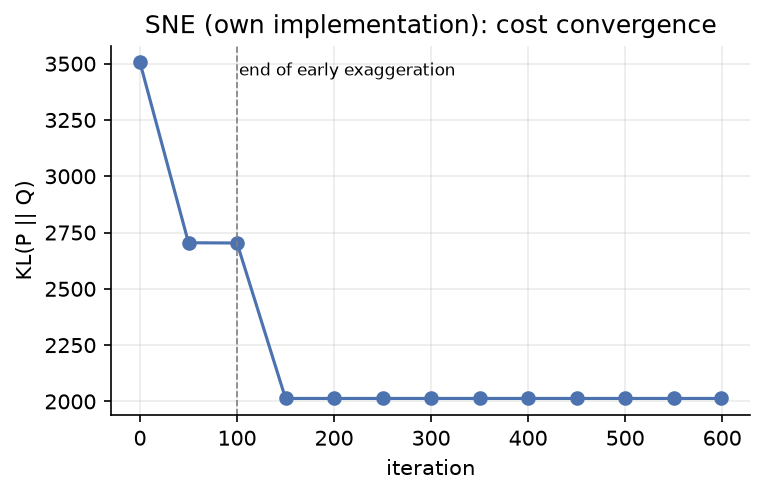

[23:32:59] === Reduction -> classification (fit on train, evaluate on test) ===
[23:33:19]   table  -> outputs/tables/red_downstream_comparison.csv
[23:33:20]   figure -> outputs/figures/red_05_downstream_comparison.png


,dims,test accuracy,test balanced acc,test macro F1,train accuracy
reduction,,,,,
None (all features),153,0.7000,0.6993,0.6804,0.8351
PCA,10,0.4717,0.5238,0.4437,0.5468
LDA,5,0.6717,0.6905,0.6236,0.7916
SVD,10,0.4717,0.4797,0.4195,0.5528
Kernel PCA (RBF),10,0.4587,0.4791,0.4121,0.5261
Isomap,10,0.4565,0.4402,0.4026,0.5011
LLE,10,0.3826,0.3787,0.3384,0.3874
UMAP,10,0.4174,0.3883,0.3586,0.4331


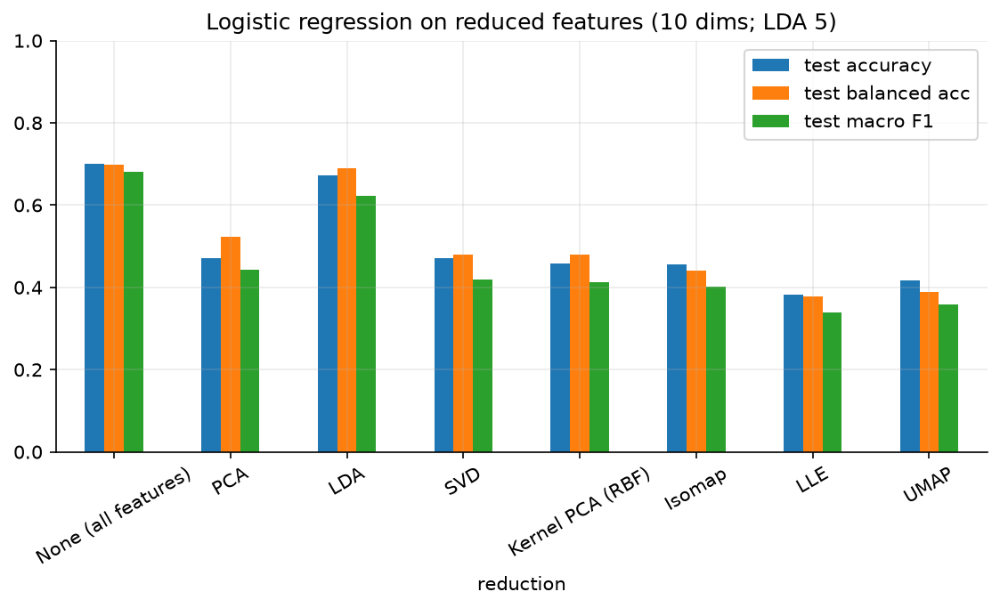

In [8]:
nonlin, emb_idx, quality = reduction.nonlinear_reduction(Xtr, ytr_lbl, fast=FAST)
display(quality)
for f in ["red_04_nonlinear_2d_diagnosis","red_04_nonlinear_2d_cancer","red_06_sne_convergence"]: show(f)
downstream = reduction.downstream_comparison(Xtr, ytr, Xte, yte, fast=FAST)
display(downstream); show("red_05_downstream_comparison")

## 6. Clustering before and after reduction

[23:33:20] === Clustering before / after reduction ===
[23:33:23]   figure -> outputs/figures/clu_01_choose_k.png
[23:33:23]   table  -> outputs/tables/clu_choose_k.csv
[23:33:35]   table  -> outputs/tables/clu_metrics_before_after.csv
[23:33:35]   best NMI (KMeans): LDA 2-D=0.453, UMAP 2-D=0.253, t-SNE 2-D=0.244
[23:33:36]   figure -> outputs/figures/clu_02_embeddings_vs_clusters.png
[23:33:37]   figure -> outputs/figures/clu_03_metrics_before_after.png
[23:33:37]   figure -> outputs/figures/clu_04_contingency_best.png


,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,purity
space,,,,,,
Original (no reduction),0.0722,2.3677,158.5351,0.0930,0.1314,0.5201
PCA 2-D,0.3321,0.8776,1278.7797,0.0347,0.0698,0.4140
LDA 2-D,0.3941,0.8244,2130.3051,0.3847,0.4525,0.7291
SVD 2-D,0.3323,0.8789,1280.9533,0.0337,0.0690,0.4119
Kernel PCA (RBF) 2-D,0.3480,0.8773,1578.4228,0.0444,0.0766,0.4412
Kernel PCA (poly) 2-D,0.3964,0.6952,1535.1536,0.0599,0.0826,0.3945
SNE 2-D,0.3433,0.8558,701.4381,0.0829,0.1331,0.5090
t-SNE 2-D,0.3774,0.8630,1785.1021,0.1726,0.2444,0.6159
Metric MDS 2-D,0.3216,0.8606,926.8946,0.0366,0.0570,0.4300


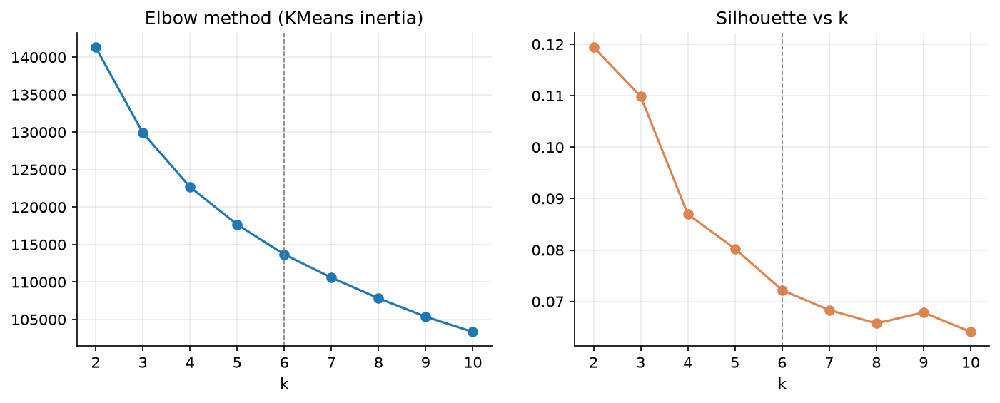

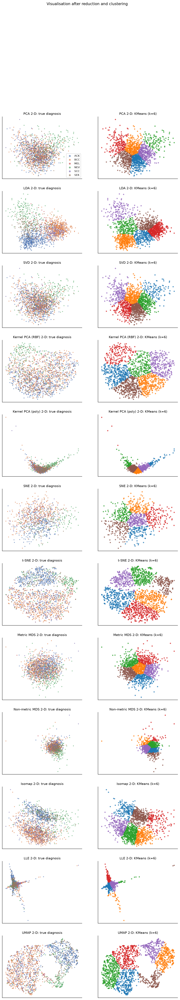

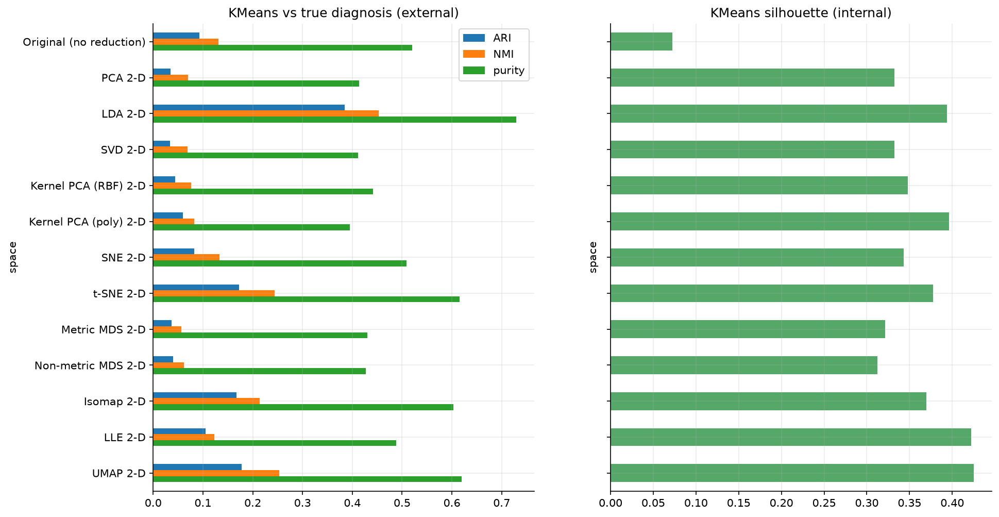

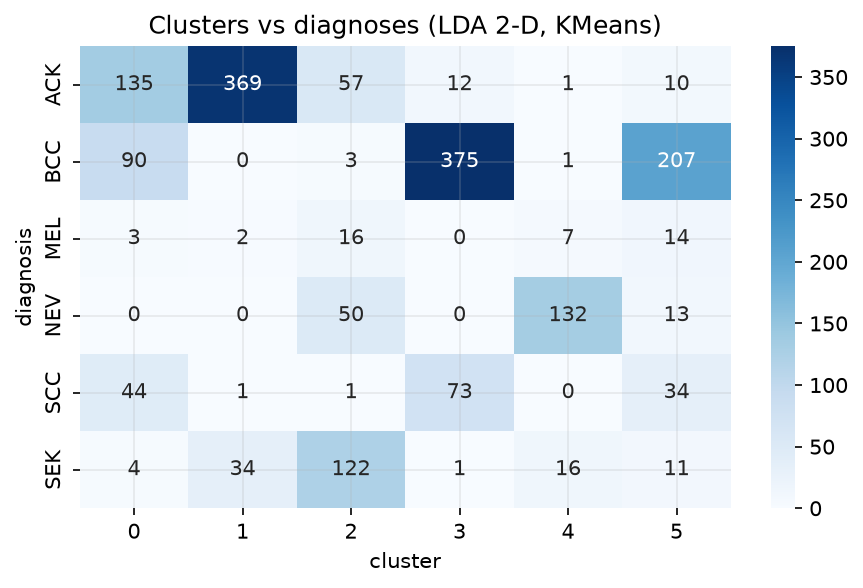

In [9]:
from src.clustering import run_clustering
clu = run_clustering(Xtr, ytr_lbl, {**lin, **nonlin}, emb_idx)
display(clu.xs("KMeans", level="algorithm"))
for f in ["clu_01_choose_k","clu_02_embeddings_vs_clusters","clu_03_metrics_before_after","clu_04_contingency_best"]: show(f)

## 7. Feature selection: filter, wrapper, embedded (L1/L2/Elastic Net), GA / PSO / SA

[23:33:37] === Feature selection ===
[23:33:38] --- Filter methods ---
[23:33:40]   table  -> outputs/tables/fs_filter_scores.csv
[23:33:41]   figure -> outputs/figures/fs_01_filter_scores.png
[23:33:41]   removed 20 low-variance, 31 redundant; kept top-30
[23:33:41] --- Wrapper methods ---
[23:34:26]   SFS forward: 15 of 40 features (45s)
[23:36:03]   SFS backward: 15 of 40 features (97s)
[23:38:11]   figure -> outputs/figures/fs_02_rfecv.png
[23:38:11]   RFECV optimum: 39 features
[23:38:11] --- Embedded methods (L1, L2, Elastic Net, RF importance) ---
[23:38:31]   L1 (Lasso): 83 features
[23:38:37]   L2 (Ridge): 20 features
[23:38:42]   Elastic Net: 112 features
[23:38:45]   table  -> outputs/tables/fs_embedded_importances.csv
[23:42:14]   figure -> outputs/figures/fs_03_embedded.png
[23:42:14] --- Metaheuristic feature selection (GA, BPSO, SA) ---
[23:43:18]   GA done (65s, 428 subsets evaluated)
[23:46:09]   BPSO done (170s)
[23:52:08]   SA done (359s)
[23:52:09]   figure -> outpu

,n_features,train CV balanced acc,train CV std,test accuracy,test balanced acc,test macro F1
method,,,,,,
All features,153,0.6623,0.0414,0.6891,0.6963,0.6696
Filter (mean rank of F/MI/chi2),30,0.6494,0.0177,0.6152,0.6705,0.5983
Wrapper: SFS forward,15,0.6709,0.0178,0.6065,0.6660,0.5729
Wrapper: SFS backward,15,0.6627,0.0160,0.5913,0.6463,0.5604
Wrapper: RFE,15,0.6278,0.0140,0.6174,0.7116,0.5825
Wrapper: RFECV,39,0.7128,0.0137,0.7000,0.7123,0.6537
Embedded: L1 (Lasso),83,0.7001,0.0129,0.6739,0.6699,0.6398
Embedded: L2 (Ridge),20,0.5856,0.0095,0.5717,0.5740,0.4984
Embedded: Elastic Net,112,0.6658,0.0348,0.6891,0.6821,0.6477


chosen: Metaheuristic: GA 56 features


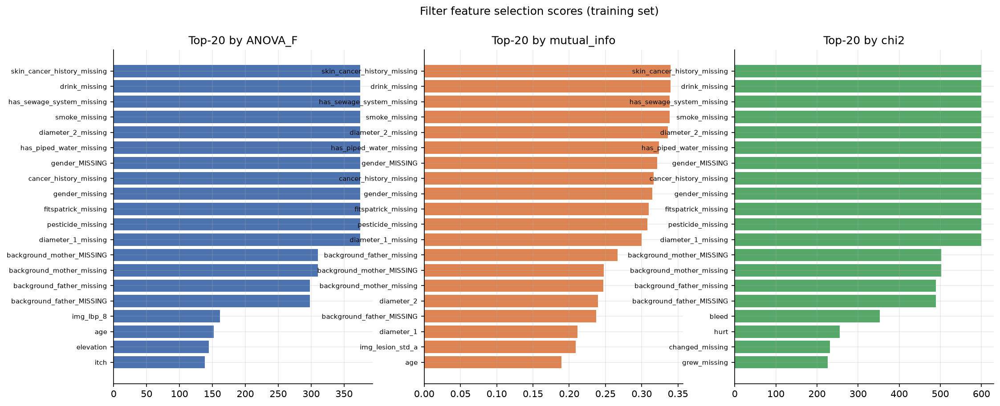

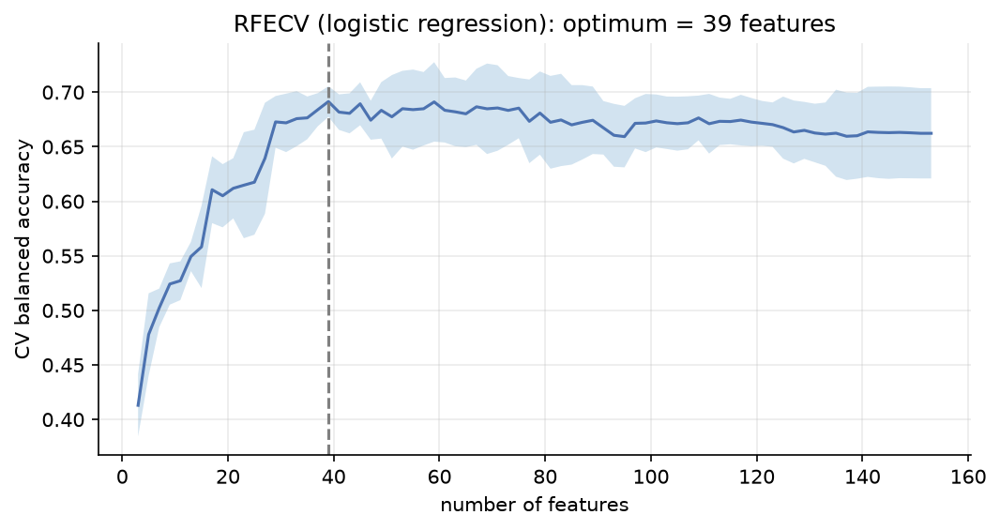

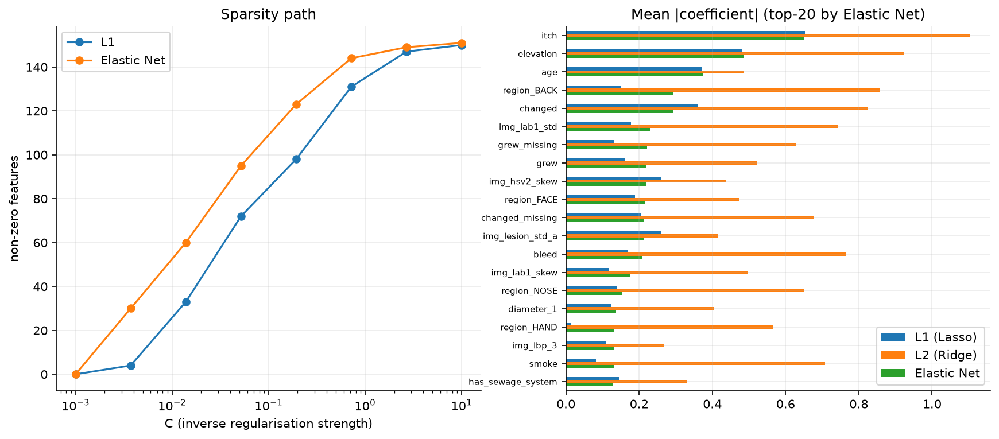

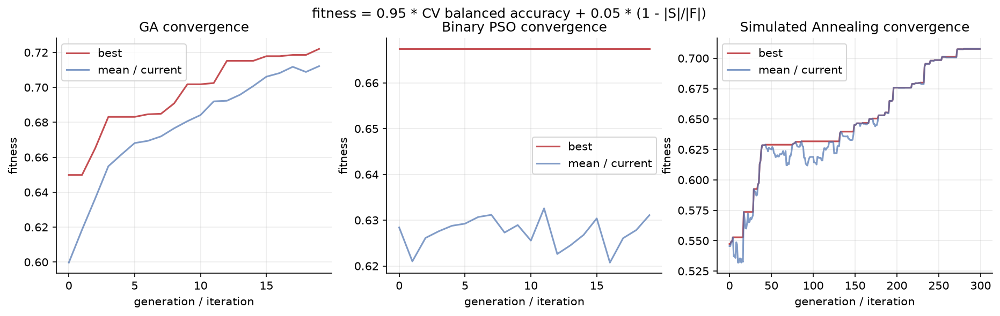

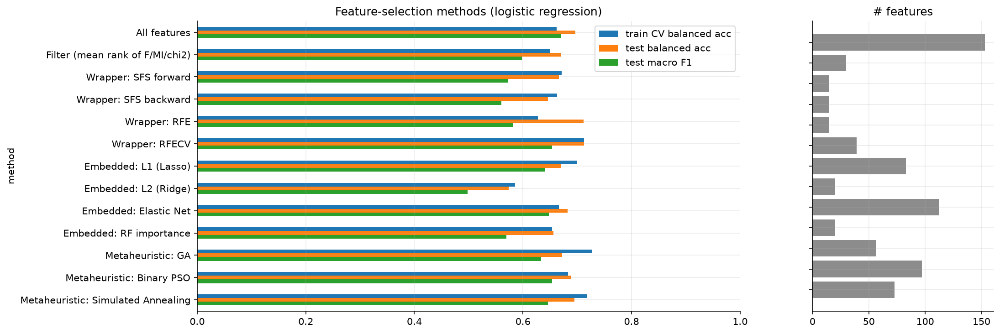

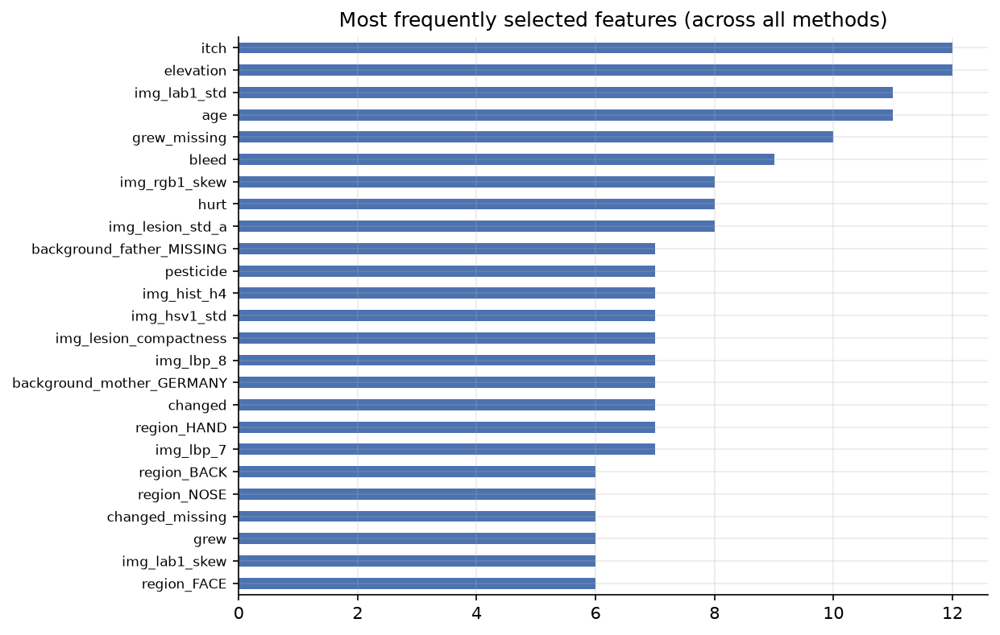

In [10]:
from src.feature_selection import run_feature_selection
subsets, fs_comp, best_subset = run_feature_selection(Xtr, ytr, train[config.GROUP].to_numpy(), Xte, yte, fast=FAST)
selected_cols = subsets[best_subset]
display(fs_comp); print("chosen:", best_subset, len(selected_cols), "features")
for f in ["fs_01_filter_scores","fs_02_rfecv","fs_03_embedded","fs_04_metaheuristics_convergence",
          "fs_05_comparison","fs_06_selection_frequency"]: show(f)

## 8. Models and evaluation (80/20 hold-out with all metrics + 5-fold cross-validation)

[23:52:44] === Model training & evaluation ===
[23:52:51]   Logistic Regression      CV acc=0.688±0.014 | test acc=0.676 bacc=0.684 F1=0.638 AUC=0.918
[23:52:55]   LDA                      CV acc=0.747±0.013 | test acc=0.709 bacc=0.604 F1=0.601 AUC=0.915
[23:52:56]   Gaussian NB              CV acc=0.199±0.022 | test acc=0.185 bacc=0.385 F1=0.214 AUC=0.804
[23:52:57]   KNN                      CV acc=0.636±0.025 | test acc=0.628 bacc=0.376 F1=0.379 AUC=0.813
[23:52:58]   Decision Tree            CV acc=0.545±0.018 | test acc=0.591 bacc=0.586 F1=0.544 AUC=0.802
[23:53:08]   Random Forest            CV acc=0.732±0.016 | test acc=0.707 bacc=0.559 F1=0.576 AUC=0.905
[23:53:15]   Extra Trees              CV acc=0.732±0.010 | test acc=0.676 bacc=0.522 F1=0.528 AUC=0.905
[23:53:40]   Hist Gradient Boosting   CV acc=0.742±0.010 | test acc=0.720 bacc=0.643 F1=0.669 AUC=0.928
[23:53:44]   SVM (RBF)                CV acc=0.703±0.020 | test acc=0.689 bacc=0.605 F1=0.616 AUC=0.914
[23:53:48]   MLP 

,CV accuracy mean,CV accuracy std,CV balanced_accuracy mean,CV balanced_accuracy std,CV f1_macro mean,CV f1_macro std,CV precision_macro mean,CV precision_macro std,CV recall_macro mean,CV recall_macro std,CV roc_auc_ovr mean,CV roc_auc_ovr std,CV train accuracy mean
model,,,,,,,,,,,,,
Logistic Regression,0.6877,0.0144,0.7130,0.0149,0.6578,0.0182,0.6412,0.0234,0.7130,0.0149,0.9267,0.0053,0.7553
LDA,0.7470,0.0135,0.6487,0.0454,0.6462,0.0302,0.6793,0.0289,0.6487,0.0454,0.9246,0.0047,0.7816
Gaussian NB,0.1991,0.0219,0.4151,0.0368,0.2228,0.0257,0.4595,0.0268,0.4151,0.0368,0.8285,0.0199,0.2101
KNN,0.6360,0.0251,0.3970,0.0202,0.4016,0.0201,0.4787,0.0462,0.3970,0.0202,0.8473,0.0152,0.9995
Decision Tree,0.5446,0.0185,0.5193,0.0370,0.4854,0.0225,0.5000,0.0172,0.5193,0.0370,0.7700,0.0215,0.7141
Random Forest,0.7323,0.0160,0.5441,0.0378,0.5607,0.0401,0.6555,0.0414,0.5441,0.0378,0.9098,0.0030,0.9965
Extra Trees,0.7323,0.0103,0.5797,0.0483,0.5930,0.0438,0.6566,0.0600,0.5797,0.0483,0.9191,0.0028,0.9947
Hist Gradient Boosting,0.7416,0.0096,0.6290,0.0172,0.6467,0.0152,0.6854,0.0248,0.6290,0.0172,0.9137,0.0063,0.9995
SVM (RBF),0.7029,0.0201,0.6180,0.0333,0.6301,0.0262,0.6609,0.0264,0.6180,0.0333,0.9119,0.0062,0.9272


,test accuracy,test error rate,test balanced accuracy,test precision (macro),test recall (macro),test F1 (macro),test precision (weighted),test recall (weighted),test F1 (weighted),test specificity (macro),...,train F1 (weighted),train specificity (macro),train MCC,train Cohen kappa,train ROC-AUC (OvR macro),train ROC-AUC (OvR weighted),train cancer sensitivity,train cancer specificity,train cancer ROC-AUC,fit diagnosis
Logistic Regression,0.6761,0.3239,0.6843,0.6306,0.6843,0.6377,0.7551,0.6761,0.6996,0.9346,...,0.7621,0.9489,0.6790,0.6712,0.9572,0.9506,0.9357,0.8976,0.9712,OVERFITTING (train-test gap +0.12 > 0.1)
LDA,0.7087,0.2913,0.6039,0.6169,0.6039,0.6006,0.7030,0.7087,0.6967,0.9317,...,0.7650,0.9471,0.6930,0.6882,0.9469,0.9415,0.9472,0.8749,0.9671,slight overfitting (gap +0.10)
Gaussian NB,0.1848,0.8152,0.3851,0.3482,0.3851,0.2141,0.4259,0.1848,0.1563,0.8551,...,0.1873,0.8599,0.1884,0.1480,0.8641,0.8640,0.9966,0.6836,0.8699,UNDERFITTING (low train and test score: model ...
KNN,0.6283,0.3717,0.3760,0.4674,0.3760,0.3791,0.5918,0.6283,0.5782,0.9088,...,0.9995,0.9999,0.9993,0.9993,1.0000,1.0000,1.0000,1.0000,1.0000,OVERFITTING (train-test gap +0.62 > 0.1)
Decision Tree,0.5913,0.4087,0.5856,0.5566,0.5856,0.5444,0.6980,0.5913,0.6217,0.9174,...,0.7447,0.9458,0.6646,0.6481,0.9609,0.9457,0.9644,0.8325,0.9553,OVERFITTING (train-test gap +0.23 > 0.1)
Random Forest,0.7065,0.2935,0.5586,0.6561,0.5586,0.5762,0.6692,0.7065,0.6639,0.9268,...,0.9962,0.9992,0.9948,0.9948,1.0000,1.0000,1.0000,0.9969,1.0000,OVERFITTING (train-test gap +0.44 > 0.1)
Extra Trees,0.6761,0.3239,0.5224,0.5678,0.5224,0.5281,0.6622,0.6761,0.6503,0.9225,...,0.9946,0.9990,0.9926,0.9926,1.0000,0.9999,1.0000,1.0000,1.0000,OVERFITTING (train-test gap +0.47 > 0.1)
Hist Gradient Boosting,0.7196,0.2804,0.6429,0.7183,0.6429,0.6688,0.7147,0.7196,0.7131,0.9353,...,0.9995,0.9999,0.9993,0.9993,1.0000,1.0000,1.0000,1.0000,1.0000,OVERFITTING (train-test gap +0.36 > 0.1)
SVM (RBF),0.6891,0.3109,0.6052,0.6425,0.6052,0.6156,0.7070,0.6891,0.6954,0.9318,...,0.9198,0.9829,0.8912,0.8898,0.9950,0.9916,0.9839,0.9545,0.9938,OVERFITTING (train-test gap +0.34 > 0.1)
MLP,0.7370,0.2630,0.5565,0.6220,0.5565,0.5615,0.7116,0.7370,0.7161,0.9390,...,0.8468,0.9655,0.8035,0.7999,0.9741,0.9716,0.9506,0.9359,0.9843,OVERFITTING (train-test gap +0.22 > 0.1)


,precision,recall,f1-score,support,specificity
ACK,0.8868,0.6438,0.7460,146.0,0.9618
BCC,0.8029,0.6509,0.7190,169.0,0.9072
MEL,0.4286,0.6000,0.5000,10.0,0.9822
NEV,0.8000,0.8980,0.8462,49.0,0.9732
SCC,0.2473,0.5897,0.3485,39.0,0.8337
SEK,0.6182,0.7234,0.6667,47.0,0.9492


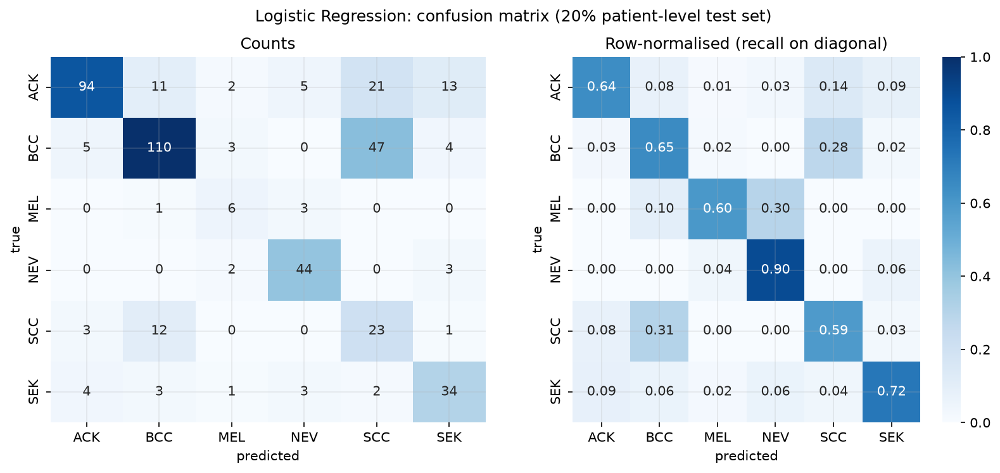

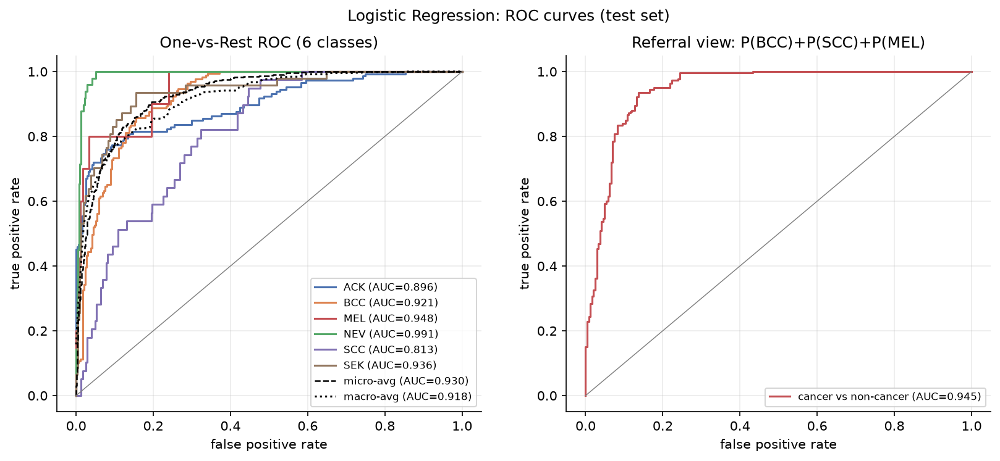

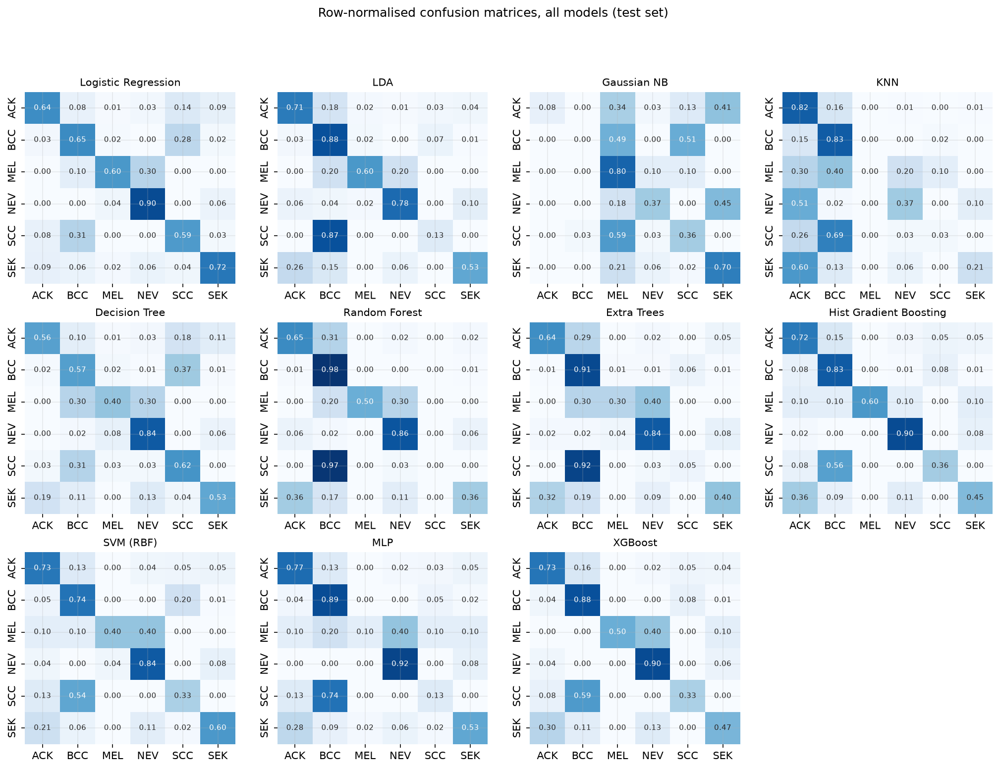

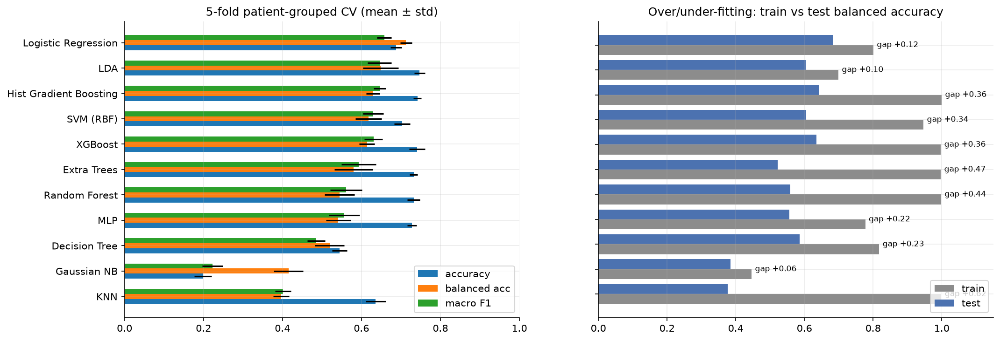

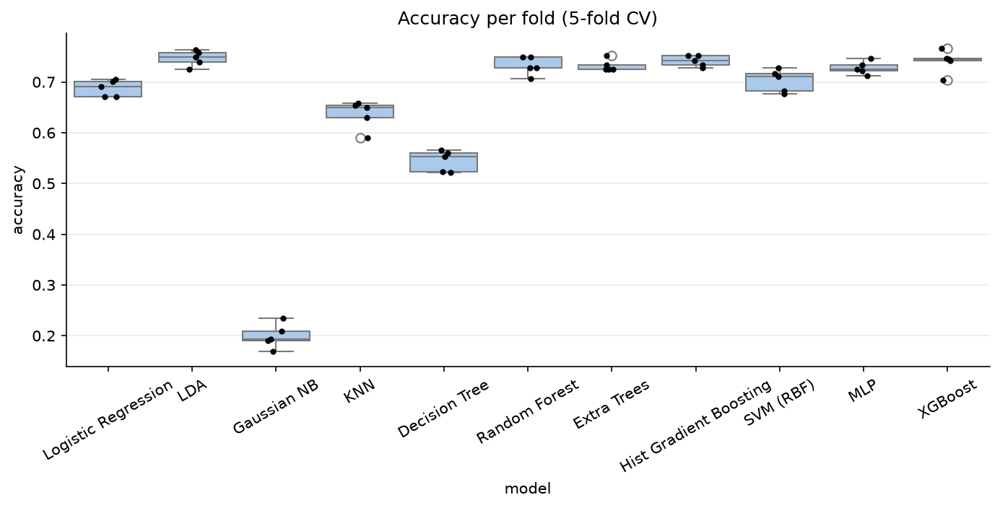

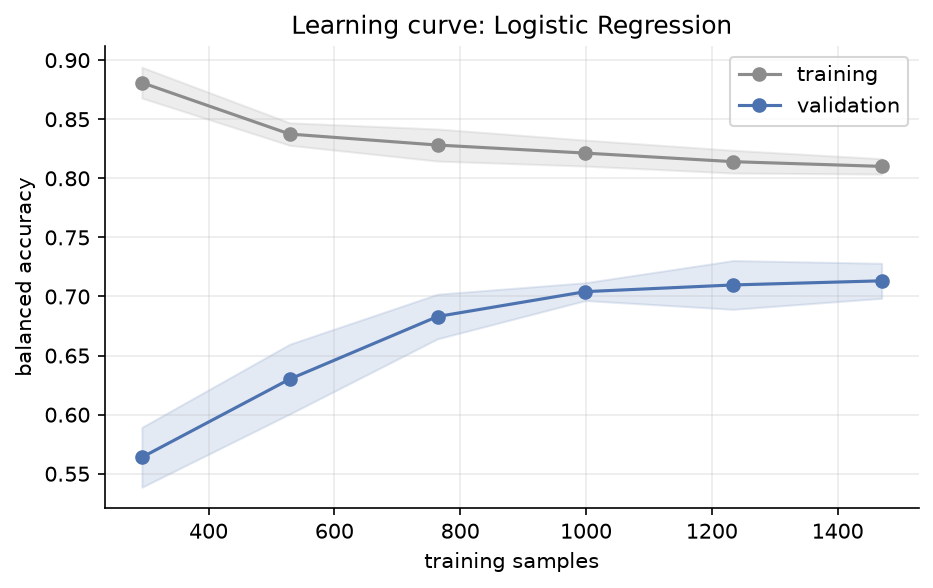

In [11]:
from src.models import get_models
from src.evaluation import evaluate_models, modality_comparison
models = get_models(fast=FAST)
ev = evaluate_models(models, prep, selected_cols, train, ytr, test, yte, smote=False)
display(ev["cv"]); display(ev["holdout"]); display(ev["per_class"])
for f in ["eval_01_confusion_matrix_best","eval_02_roc_best","eval_03_confusion_all_models",
          "eval_04_model_comparison","eval_05_cv_folds","eval_06_learning_curve"]: show(f)

[23:54:16] === Modality comparison with Logistic Regression ===
[23:54:24]   table  -> outputs/tables/eval_modality_comparison.csv
[23:54:24]   figure -> outputs/figures/eval_07_modality_comparison.png


,accuracy,error rate,balanced accuracy,precision (macro),recall (macro),F1 (macro),precision (weighted),recall (weighted),F1 (weighted),specificity (macro),MCC,Cohen kappa,ROC-AUC (OvR macro),ROC-AUC (OvR weighted),cancer sensitivity,cancer specificity,cancer ROC-AUC
Clinical data only,0.6587,0.3413,0.7196,0.6098,0.7196,0.6280,0.7406,0.6587,0.6797,0.9315,0.5745,0.5631,0.9116,0.9078,0.9083,0.8140,0.9393
Image features only,0.4652,0.5348,0.4161,0.4052,0.4161,0.3909,0.5640,0.4652,0.4891,0.8906,0.3319,0.3217,0.7837,0.7932,0.6606,0.7727,0.7867
Early fusion (all features),0.6913,0.3087,0.7064,0.6666,0.7064,0.6735,0.7485,0.6913,0.7108,0.9359,0.6028,0.5960,0.9271,0.9232,0.9128,0.8554,0.9505
Early fusion + feature selection,0.6761,0.3239,0.6843,0.6306,0.6843,0.6377,0.7551,0.6761,0.6996,0.9346,0.5925,0.5819,0.9176,0.9136,0.9266,0.8264,0.9451
Late fusion (mean probabilities),0.6413,0.3587,0.6346,0.5732,0.6346,0.5829,0.7172,0.6413,0.6662,0.9274,0.5451,0.5371,0.9056,0.9009,0.8624,0.8306,0.9269


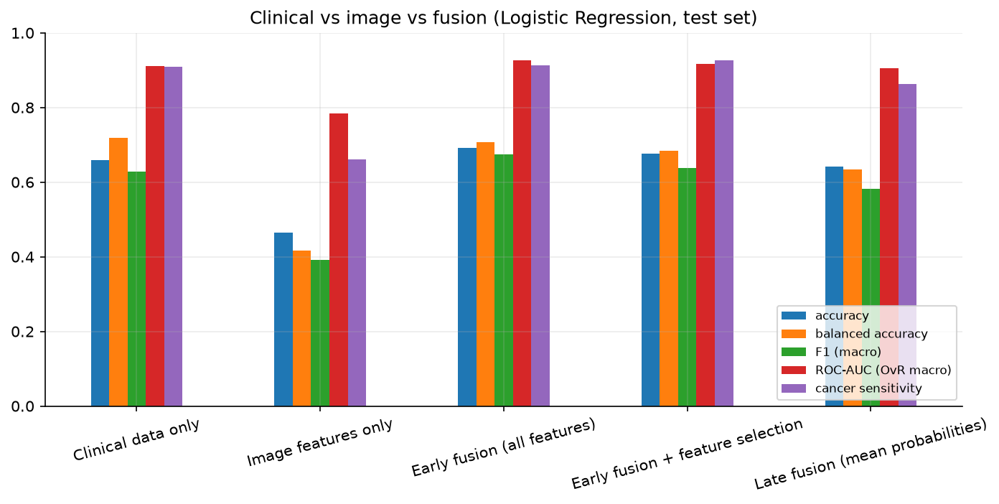

In [12]:
modality = modality_comparison(models[ev["best"]], make_prep, train, ytr, test, yte, selected_cols, ev["best"])
display(modality); show("eval_07_modality_comparison")

### Interpretation
*(Fill in from the outputs above. `outputs/REPORT.md` has an auto-generated draft.)*
* **Confusion matrix:** which classes are confused (expected: ACK↔SCC, NEV↔MEL, BCC↔SCC) and the recall of the rare, dangerous MEL class.
* **Over/underfitting:** compare train and test balanced accuracy (right panel of `eval_04`) and the learning curve. A large gap means overfitting (common for trees and KNN); low scores on both means underfitting.
* **Comparisons:** linear vs non-linear models, clinical vs image vs fusion, and with vs without feature selection.

## 9. Comparison with related work

In [13]:
from src.report import related_work_table, write_report
b = ev["holdout"].loc[ev["best"]]
related = related_work_table({"model": ev["best"], "selection": best_subset, "accuracy": b["test accuracy"],
    "bacc": b["test balanced accuracy"], "f1": b["test F1 (macro)"], "auc": b["test ROC-AUC (OvR macro)"]})
display(related)

[23:54:24]   table  -> outputs/tables/related_work_comparison.csv


,work,method,data,task,reported result,source
0,"Pacheco et al., Data in Brief 2020 (dataset pa...",Dataset release; baselines in companion paper ...,images + metadata,6-class,see Pacheco & Krohling 2020 (ResNet + metadata...,https://pmc.ncbi.nlm.nih.gov/articles/PMC7479321/
1,"Yin et al., 2022",Dense CNN with metadata fusion,images + metadata,6-class,balanced accuracy 81.4%,https://pmc.ncbi.nlm.nih.gov/articles/PMC9806866/
2,"Diffusion models for skin & oral cancer, 2025 ...",Diffusion-based classifier,images,6-class / binary,"balanced accuracy 64.6% (6-class), 83.6% (binary)",https://arxiv.org/abs/2504.00026
3,"MiSC, Multimedia Tools & Applications 2025","EfficientNet-B4, late fusion with metadata",images (+ metadata),6-class,accuracy 79.4% image-only; +9.8 points with me...,https://link.springer.com/article/10.1007/s110...
4,"AI-driven early detection (Authorea preprint, ...",EfficientNet-B3 / ResNet-50 + multimodal fusion,images + metadata,6-class,"accuracy 82.5% (EffNet-B3), 78.2% (ResNet-50)",https://www.authorea.com/doi/10.22541/au.17588...
5,"Islam et al., 2026",EfficientNet-B2 + DER + metadata,images + metadata,cancer vs non-cancer,"sensitivity 99.5%, specificity 74.7%",https://aru.figshare.com/articles/journal_cont...
6,This project (Phase 1),Logistic Regression on hand-crafted image + cl...,images + metadata (patient-level split),6-class,"accuracy 67.6%, balanced accuracy 68.4%, macro...",this repository


> Literature numbers come from search-result abstracts. **Verify them against the papers before submission.** Most papers fine-tune CNNs on raw pixels and split by image, not by patient, so the comparison is indicative only.